# FDTD for periodic structures: gratings, resonant filters and photonic crystals

Many optical structures repeat: gratings, resonant waveguide filters,
metasurfaces, photonic crystals. Their period lets one unit cell stand for
the whole structure, with **Bloch-periodic boundaries**: what leaves the
cell on one side comes back on the other with a phase,
$F(x + L) = F(x)\,e^{ikL}$. This notebook (continuing notebooks
[57](57_fdtd_basics.ipynb), [59](59_fdtd_metals_plasmons.ipynb) and
[60](60_fdtd_photonic_circuits.ipynb)) covers

1. Bloch boundaries and oblique incidence: a slab against `thin_films`,
2. diffraction gratings: efficiencies of all orders against RCWA
   (`litho.rcwa`), Rayleigh anomalies,
3. a guided-mode resonance filter: a sub-wavelength grating on a thin
   waveguide that reflects a narrow band,
4. photonic crystals: band structures of a Bragg stack (exact) and of a
   square lattice of rods, its band gap, and the fields at the band edges.

Lengths are in µm (or in units of the period), times in µm/c.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

from pyoptics import fdtd
from pyoptics.fdtd import plot as fplot
from pyoptics.litho.rcwa import rcwa, Layer
from pyoptics.thin_films import r_t_coeffs

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
print("numba kernels available:", fdtd.numba_available)
GLASS = fdtd.Medium.from_index(1.5)
t_start = time.perf_counter()

numba kernels available: True


## 1. Bloch boundaries and oblique incidence

A plane wave $e^{i(k_x x + k_y y - \omega t)}$ hitting a structure that is
periodic in x keeps its $k_x$ (up to multiples of $2\pi/L$, the
diffraction orders). With `fdtd.Bloch(k)` on the x axis, every field obeys
$F(x + L) = F(x)\,e^{ikL}$; the fields become complex (the updates stay
the real Yee updates, only the wrap-around carries the phase). A line
source across the cell then carries $e^{ikx}$ and launches plane waves with
$k_x = k$.

The angle of these waves depends on the frequency: $\sin\theta = k/(n k_0)$.
A pulse covers a range of angles at once, each wavelength at its own
angle, which is fine for comparisons as long as one keeps track of it. A
glass slab ($n$ = 2, 400 nm) at $k = k_0\sin 30°$ for $\lambda_0$ = 1 µm,
against the Airy formula of `thin_films` at the angle of each wavelength:

Ez: max |R - R_thin_films| = 1.7e-03, max |R + T - 1| = 4.7e-03


Hz: max |R - R_thin_films| = 1.2e-03, max |R + T - 1| = 3.2e-03


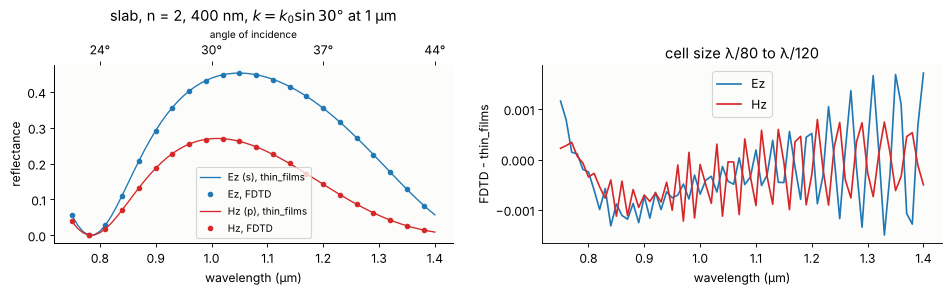

In [2]:
def two_runs(grid, structure, mode, bnd, wls, src_y=2.0, mon=(1.5, -1.5), time_=50, max_order=10):
    # reference run (no structure) and structure run; returns orders of the
    # reflection (scattered field above) and transmission (below), divided by
    # the incident power
    out = []
    for st in ([], structure):
        src = fdtd.LineSource(src_y, fdtd.GaussianPulse(1.0, 0.2), axis=1)
        top = fdtd.DiffractionMonitor(mon[0], wls, max_order=max_order)
        bot = fdtd.DiffractionMonitor(mon[1], wls, max_order=max_order)
        sim = fdtd.Simulation(grid, st, [src], [top, bot], mode=mode, boundaries=bnd)
        sim.run(time=time_)
        out.append((top, bot, sim))
    (rt, rb, _), (top, bot, sim) = out
    P = rb.orders().order(0)
    R = -top.orders(rt).power/P[:, None]
    T = bot.orders().power/P[:, None]
    return top.orders().m, R, T, sim


wls = np.linspace(0.75, 1.4, 66)
k = 2*np.pi*np.sin(np.radians(30))
slab = [(fdtd.Slab(-0.4, 0.0, axis=1), fdtd.Medium.from_index(2.0))]
grid = fdtd.Grid((0.25, 6.0), 0.00625)
theta = np.arcsin(k*wls/(2*np.pi))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for mode, pol, color in (("Ez", "s", "C0"), ("Hz", "p", "C3")):
    m, R, T, _ = two_runs(grid, slab, mode, (fdtd.Bloch(k), "pml"), wls)
    i0 = list(m).index(0)
    ref = np.array([abs(r_t_coeffs(th, [2.0], [0], [0.4], 1.0, 0, 1.0, 0, pol, wl)[0])**2
                    for th, wl in zip(theta, wls)])
    ax[0].plot(wls, ref, color=color, lw=1.2, label="%s (%s), thin_films" % (mode, pol))
    ax[0].plot(wls[::3], R[::3, i0], "o", color=color, ms=4, label="%s, FDTD" % mode)
    ax[1].plot(wls, R[:, i0] - ref, color=color, label=mode)
    print("%s: max |R - R_thin_films| = %.1e, max |R + T - 1| = %.1e"
          % (mode, np.max(np.abs(R[:, i0] - ref)), np.max(np.abs(R.sum(1) + T.sum(1) - 1))))
ax[0].set(xlabel="wavelength (µm)", ylabel="reflectance",
          title=r"slab, n = 2, 400 nm, $k = k_0 \sin 30°$ at 1 µm")
ax[0].legend(fontsize=9)
ax2 = ax[0].twiny()
ax2.set_xlim(ax[0].get_xlim())
ticks = np.array([0.8, 1.0, 1.2, 1.4])
ax2.set_xticks(ticks, ["%.0f°" % np.degrees(np.arcsin(k*t/(2*np.pi))) for t in ticks])
ax2.set_xlabel("angle of incidence", fontsize=9)
ax[1].set(xlabel="wavelength (µm)", ylabel="FDTD - thin_films", title="cell size λ/80 to λ/120")
ax[1].legend()
plt.tight_layout()

The Ez polarization (E along z, s in thin-film terms) and the Hz
polarization (p) both follow the Airy formula across the band and its
angles (from 22° to 44°), to the second-order discretization error of
about 2e-3. p-light reflects less, on its way to the Brewster angle
(63°).

`fdtd.DiffractionMonitor` does the bookkeeping: it takes the DFT of the
transverse E and H on a line across the cell, expands both into the
orders $k_m = k + 2\pi m/L$ and returns the power of each order. The
reflected orders need the incident field removed, which comes from a
reference run without the structure.

## 2. Diffraction gratings against RCWA

A lamellar glass grating (period 1.5 µm, 500 nm deep, half filled) on a
glass substrate, at normal incidence. `litho.rcwa` computes the same
grating with the Fourier modal method; the Ez polarization (E along the
grooves) is its TE case.

Ez, normal incidence: |FDTD - RCWA| over the orders shown: median 0.0010, largest 0.0190 at 1.500 µm


Hz, normal incidence: |FDTD - RCWA| over the orders shown: median 0.0010, largest 0.0078 at 1.500 µm


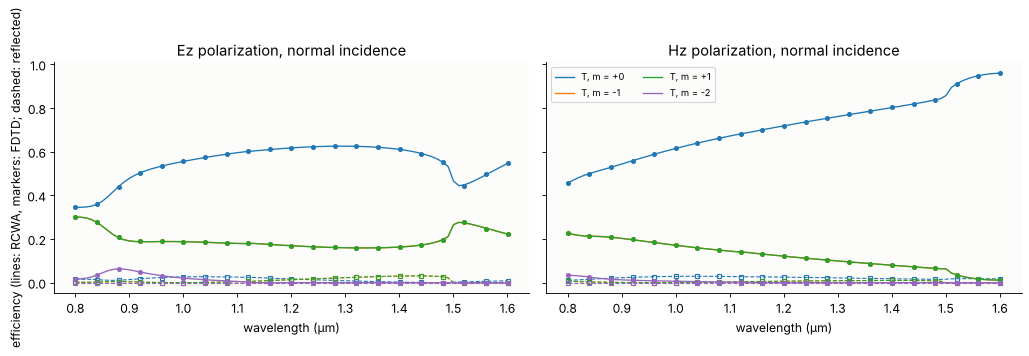

In [3]:
P_g, depth, fill = 1.5, 0.5, 0.5
grating = [(fdtd.Slab(-10, -depth, axis=1), GLASS), (fdtd.Rect((0, -depth/2), (fill*P_g, depth)), GLASS)]
layers = [Layer(depth, 1.0, [(0.0, fill*P_g, 1.5)])]
wls_g = np.linspace(0.8, 1.6, 81) + 1e-4      # off the Rayleigh wavelengths, where RCWA divides by 0


def compare(theta_deg, title):
    k = 2*np.pi*np.sin(np.radians(theta_deg))
    bnd = (fdtd.Bloch(k) if k else "periodic", "pml")
    fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
    for a, (mode, jones) in zip(ax, (("Ez", (0, 1)), ("Hz", (1, 0)))):
        m, R, T, sim = two_runs(fdtd.Grid((P_g, 6.0), 0.02), grating, mode, bnd, wls_g)
        rc = [rcwa(P_g, layers, wl, k_x=k*wl/(2*np.pi), n_in=1.0, n_out=1.5, n_orders=25)
              .efficiencies(jones) for wl in wls_g]
        Rr = np.array([r[0][0] for r in rc])
        Tr = np.array([r[1][0] for r in rc])
        mr = np.arange(-25, 26)
        err = np.zeros(len(wls_g))
        for order, color in ((0, "C0"), (-1, "C1"), (1, "C2"), (-2, "C4")):
            i, ir = list(m).index(order), list(mr).index(order)
            a.plot(wls_g, Tr[:, ir], color=color, lw=1.2, label="T, m = %+d" % order)
            a.plot(wls_g[::4], T[::4, i], "o", color=color, ms=3.5)
            a.plot(wls_g, Rr[:, ir], "--", color=color, lw=1)
            a.plot(wls_g[::4], R[::4, i], "s", color=color, ms=3, mfc="none")
            err = np.maximum(err, np.maximum(np.abs(T[:, i] - Tr[:, ir]), np.abs(R[:, i] - Rr[:, ir])))
        a.set(xlabel="wavelength (µm)", title="%s polarization, %s" % (mode, title))
        print("%s, %s: |FDTD - RCWA| over the orders shown: median %.4f, largest %.4f at %.3f µm"
              % (mode, title, np.median(err), err.max(), wls_g[np.argmax(err)]))
    ax[0].set_ylabel("efficiency (lines: RCWA, markers: FDTD; dashed: reflected)")
    ax[1].legend(fontsize=8.5, ncol=2)
    plt.tight_layout()
    return sim


sim_g = compare(0.0, "normal incidence")

The two methods agree to about 1e-3 in every order at most wavelengths,
in both polarizations. The exception is the Rayleigh wavelength
$\lambda = P = 1.5$ µm (below): there the ±1 orders run along the surface,
ring for a long time and need a much longer run than the 40 µm/c used here
(the error reaches 0.02 within about 30 nm of
it, and 1e-3 elsewhere). One FDTD run per polarization gives the
whole spectrum; RCWA solves each wavelength separately (and is far
faster for a single one: the two methods have their strengths).

At $\lambda = P = 1.5$ µm the first orders in air turn grazing and vanish
(a **Rayleigh anomaly**); in the glass they persist up to
$\lambda = nP = 2.25$ µm. At oblique incidence the anomalies split, to
$\lambda = P(1 \pm \sin\theta)$ for the orders ±1 in air, and the
efficiencies have kinks there (**Wood anomalies**). At 20° (at 1 µm; the
angle again varies across the band):

Ez, 20° at 1 µm: |FDTD - RCWA| over the orders shown: median 0.0012, largest 0.0059 at 0.990 µm


Hz, 20° at 1 µm: |FDTD - RCWA| over the orders shown: median 0.0011, largest 0.0028 at 0.990 µm


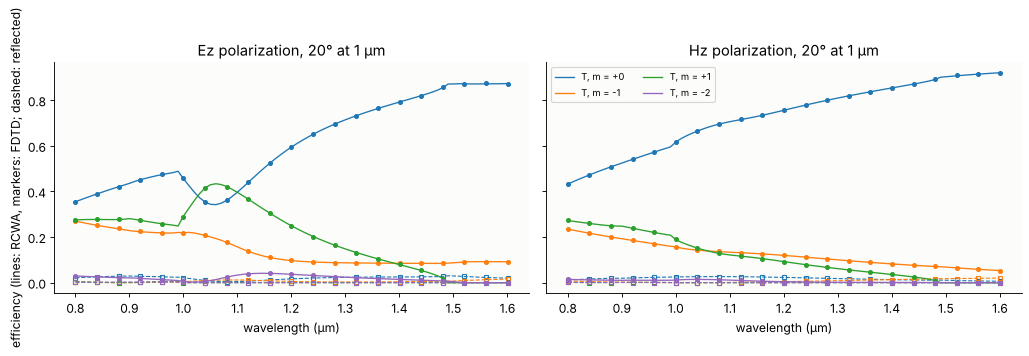

In [4]:
sim_g = compare(20.0, "20° at 1 µm")

## 3. A guided-mode resonance filter

A grating that is too fine to diffract into the air (period below the
wavelength) can still couple light into a waveguide underneath when one
of its orders matches the waveguide mode, $2\pi/P \approx n_\mathrm{eff} k_0$.
The guided light leaks back out through the grating and interferes with
the directly reflected light: a narrow reflection peak of nearly 100 %
appears on a weak background. Such **resonant waveguide gratings** are
used as narrow-band filters, laser mirrors and label-free biosensors.

Here: a 150 nm thick layer of n = 2 on glass (n = 1.45) with a grating of
80 nm deep n = 2 ridges on top (period 600 nm, half filled), at normal
incidence.

Ez: peak at 0.9691 µm (RCWA 0.9691 µm), R = 1.000 (RCWA 0.998)


Hz: peak at 0.8971 µm (RCWA 0.8961 µm), R = 0.984 (RCWA 0.999)


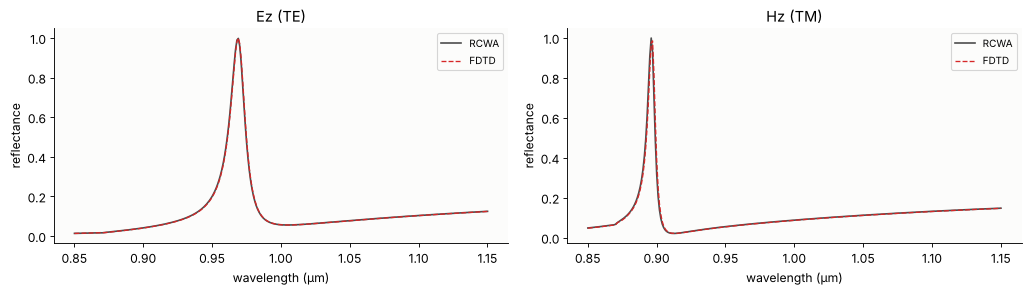

In [5]:
P_r = 0.6
gmr = [(fdtd.Slab(-10, -0.15, axis=1), fdtd.Medium.from_index(1.45)),
       (fdtd.Slab(-0.15, 0.0, axis=1), fdtd.Medium.from_index(2.0)),
       (fdtd.Rect((0, 0.04), (0.3, 0.08)), fdtd.Medium.from_index(2.0))]
gmr_layers = [Layer(0.08, 1.0, [(0.0, 0.3, 2.0)]), Layer(0.15, 2.0)]
wls_r = np.linspace(0.85, 1.15, 301) + 1e-4
grid_r = fdtd.Grid((P_r, 4.0), 0.01)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
peaks = {}
for a, (mode, jones, name) in zip(ax, (("Ez", (0, 1), "Ez (TE)"), ("Hz", (1, 0), "Hz (TM)"))):
    m, R, T, sim_r = two_runs(grid_r, gmr, mode, ("periodic", "pml"),
                              wls_r, src_y=1.2, mon=(0.8, -1.0), time_=400)
    Rr = np.array([rcwa(P_r, gmr_layers, wl, n_in=1.0, n_out=1.45, n_orders=20)
                   .efficiencies(jones)[0][0].sum() for wl in wls_r])
    a.plot(wls_r, Rr, color="0.3", lw=1.5, label="RCWA")
    a.plot(wls_r, R.sum(1), "--", color="C3", lw=1.2, label="FDTD")
    i = np.argmax(R.sum(1))
    peaks[mode] = wls_r[i]
    a.set(xlabel="wavelength (µm)", ylabel="reflectance", title=name)
    a.legend(fontsize=9)
    print("%s: peak at %.4f µm (RCWA %.4f µm), R = %.3f (RCWA %.3f)"
          % (mode, wls_r[i], wls_r[np.argmax(Rr)], R.sum(1)[i], Rr.max()))
plt.tight_layout()

FDTD and RCWA find the same narrow peaks: about 13 nm wide in Ez, 6 nm in
Hz, at different wavelengths because the TE and TM modes of the layer
have different effective indices. The Ez peak agrees to 0.1 nm; the
narrower Hz peak sits 1 nm to the red in the FDTD, the discretization
error of the 10 nm grid on 80 nm ridges, which a narrow resonance makes
visible. The FDTD runs need a few
hundred µm/c, several lifetimes of the guided resonance. The field on
resonance shows the standing wave of the two counter-propagating guided
modes in the layer:

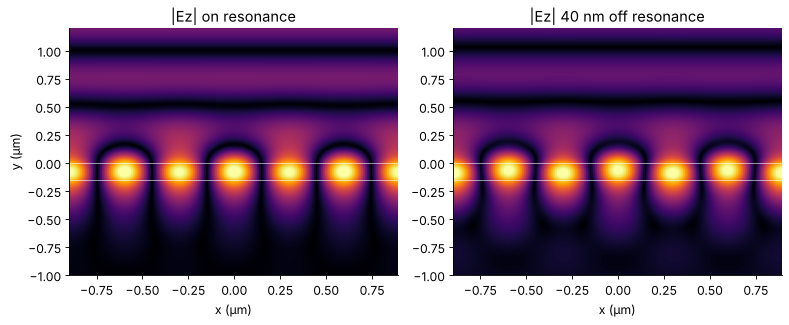

In [6]:
dft = fdtd.DFTField([peaks["Ez"], peaks["Ez"] + 0.04], components=["Ez"])
sim = fdtd.Simulation(fdtd.Grid((P_r, 4.0), 0.01), gmr,
                      [fdtd.LineSource(1.2, fdtd.ContinuousWave(peaks["Ez"], ramp=20), axis=1)], [dft],
                      boundaries=("periodic", "pml"))
sim.run(time=250)
x, y = dft.coords("Ez")
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
for a, k_, name in zip(ax, (0, 1), ("on resonance", "40 nm off resonance")):
    F = np.abs(dft.field("Ez")[k_])
    F = np.tile(F, (3, 1))                       # three periods
    xs = np.concatenate([x - P_r, x, x + P_r])
    a.imshow(F.T, origin="lower", extent=(xs[0], xs[-1], y[0], y[-1]), cmap="inferno",
             aspect="auto", vmax=np.percentile(F, 99.8))
    a.axhline(0.0, color="w", lw=0.5)
    a.axhline(-0.15, color="w", lw=0.5)
    a.set(ylim=(-1.0, 1.2), xlabel="x (µm)", title="|Ez| %s" % name)
ax[0].set_ylabel("y (µm)")
plt.tight_layout()

On resonance the guided standing wave in the layer is strong, and above
the grating the incident and the (almost totally) reflected wave form a
standing wave of nearly full contrast. 40 nm away the reflection is
about 5 % and the fringes above the grating fade.

## 4. Photonic crystals

In a periodic medium the modes are Bloch waves $u_k(x)\,e^{ikx}$ with a
periodic $u_k$, and the frequencies $\omega_n(k)$ form bands. Where no band
exists, light cannot propagate: a **photonic band gap**. `fdtd.bloch_modes()`
finds the bands: the unit cell with Bloch boundaries at wave vector $k$,
a few dipoles at random positions excite all modes, and the matrix pencil
method (`fdtd.resonances`, notebook 60) reads their frequencies off the
ring-down at a few probes. Frequencies are $\omega a/2\pi c = a/\lambda$
for the lattice constant $a$.

**1D: a Bragg stack**, layers of n = 1 and n = 3 of equal thickness. The
exact bands follow from the transfer matrix of one period,
$\cos ka = \cos k_1 d_1 \cos k_2 d_2 - \tfrac12\left(\tfrac{n_1}{n_2} + \tfrac{n_2}{n_1}\right)\sin k_1 d_1 \sin k_2 d_2$:

max |dispersion relation residual| at the FDTD frequencies: 2.7e-03


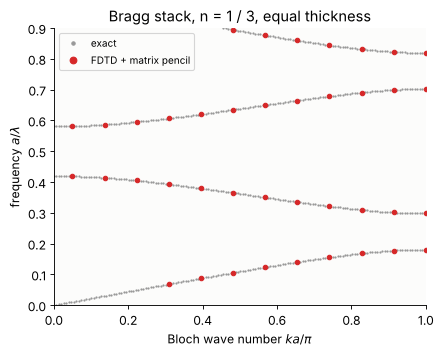

In [7]:
n1, n2, d1, d2 = 1.0, 3.0, 0.5, 0.5


def disp(w, k):
    a, b = n1*w*d1, n2*w*d2
    return np.cos(a)*np.cos(b) - 0.5*(n1/n2 + n2/n1)*np.sin(a)*np.sin(b) - np.cos(k)


ks = np.linspace(0.05, 1.0, 12)*np.pi
grid1 = fdtd.Grid(1.0, 0.005)
stack = [(fdtd.Slab(-0.25, 0.25), fdtd.Medium.from_index(n2))]
fig, ax = plt.subplots(figsize=(6, 4.5))
kk = np.linspace(0, np.pi, 300)
ws = np.linspace(1e-3, 2*np.pi*0.9, 3000)
for k_ in kk[::2]:
    v = disp(ws, k_)
    roots = [brentq(disp, ws[i], ws[i + 1], args=(k_,)) for i in np.nonzero(np.sign(v[:-1]) != np.sign(v[1:]))[0]]
    ax.plot([k_/np.pi]*len(roots), np.array(roots)/(2*np.pi), ".", color="0.6", ms=2)
err = 0.0
for k_ in ks:
    r = fdtd.bloch_modes(grid1, stack, k_, band=(1/0.9, 1/0.05), time=300)
    ax.plot([k_/np.pi]*len(r), r.frequency, "o", color="C3", ms=4)
    v = disp(2*np.pi*r.frequency, k_)
    err = max(err, np.max(np.abs(v)))
ax.plot([], [], ".", color="0.6", label="exact")
ax.plot([], [], "o", color="C3", label="FDTD + matrix pencil")
ax.set(xlabel=r"Bloch wave number $k a/\pi$", ylabel=r"frequency $a/\lambda$", xlim=(0, 1), ylim=(0, 0.9),
       title="Bragg stack, n = 1 / 3, equal thickness")
ax.legend(loc="upper left", fontsize=9)
print("max |dispersion relation residual| at the FDTD frequencies: %.1e" % err)

The FDTD bands lie on the exact ones; between them are the gaps (Bragg
reflection: at the zone edge $k = \pi/a$ a wave and its reflection are
degenerate, and the periodic index splits them).

**2D: a square lattice of rods** (ε = 8.9, radius 0.2a, the example of
Joannopoulos et al., *Photonic Crystals*, ch. 5), along the edge of the
irreducible Brillouin zone Γ → X → M → Γ, for both polarizations. Near Γ
the lowest band falls below the frequency range of the search.

Ez gap: 0.323 to 0.442, gap/midgap = 31.3 % (Joannopoulos et al.: 31.4 %)


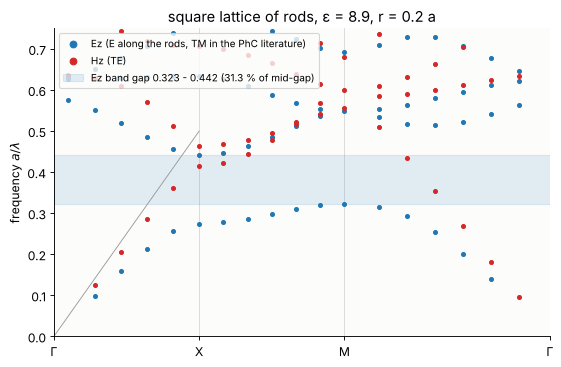

In [8]:
grid2 = fdtd.Grid((1.0, 1.0), 1/32)
rods = [(fdtd.Circle((0, 0), 0.2), fdtd.Medium(8.9))]
n_seg = 6
path = ([(np.pi*s, 0.0) for s in np.linspace(0.1, 1, n_seg)] +
        [(np.pi, np.pi*s) for s in np.linspace(1/n_seg, 1, n_seg)] +
        [(np.pi*s, np.pi*s) for s in np.linspace(1 - 1/n_seg, 0.15, n_seg)])
dist = np.concatenate([[0], np.cumsum(np.linalg.norm(np.diff(np.array(path), axis=0), axis=1))])
dist += 0.1*np.pi
bands = {}
for mode in ("Ez", "Hz"):
    bands[mode] = [fdtd.bloch_modes(grid2, rods, k_, band=(1/0.75, 1/0.08), mode=mode).frequency
                   for k_ in path]

fig, ax = plt.subplots(figsize=(8, 5))
for mode, color, name in (("Ez", "C0", "Ez (E along the rods, TM in the PhC literature)"),
                          ("Hz", "C3", "Hz (TE)")):
    for d, f in zip(dist, bands[mode]):
        ax.plot([d]*len(f), f, "o", color=color, ms=3.5)
    ax.plot([], [], "o", color=color, label=name)
# band 1 peaks at M, band 2 has its minimum at X (near Gamma band 1 lies below the search range)
lower = bands["Ez"][2*n_seg - 1][0]
upper = bands["Ez"][n_seg - 1][1]
ax.axhspan(lower, upper, color="C0", alpha=0.12,
           label="Ez band gap %.3f - %.3f (%.1f %% of mid-gap)"
           % (lower, upper, 100*(upper - lower)/(0.5*(upper + lower))))
ax.plot([0, np.pi], [0, 0.5], color="0.6", lw=0.8)       # light line along Gamma-X in vacuum
xt = [0, np.pi, 2*np.pi, (2 + np.sqrt(2))*np.pi]
ax.set_xticks(xt, ["Γ", "X", "M", "Γ"])
for x_ in xt:
    ax.axvline(x_, color="0.85", lw=0.8, zorder=0)
ax.set(xlim=(0, xt[-1]), ylim=(0, 0.75), ylabel=r"frequency $a/\lambda$",
       title="square lattice of rods, ε = 8.9, r = 0.2 a")
ax.legend(loc="upper left", fontsize=9)
print("Ez gap: %.3f to %.3f, gap/midgap = %.1f %% (Joannopoulos et al.: 31.4 %%)"
      % (lower, upper, 100*(upper - lower)/(0.5*(upper + lower))))

The Ez polarization has a complete band gap between the first and second
bands, 31 % of its mid-gap frequency like in the book; the Hz polarization
has none for this lattice (isolated rods cannot confine the in-plane E,
which has to cross the rod surfaces). The gap opens because the two
lowest modes at the zone edge put their energy into different places. At
X the first band concentrates its field in the rods (the **dielectric
band**, lower frequency), the second has it in the air between them (the
**air band**):

total run time of the notebook: 288 s


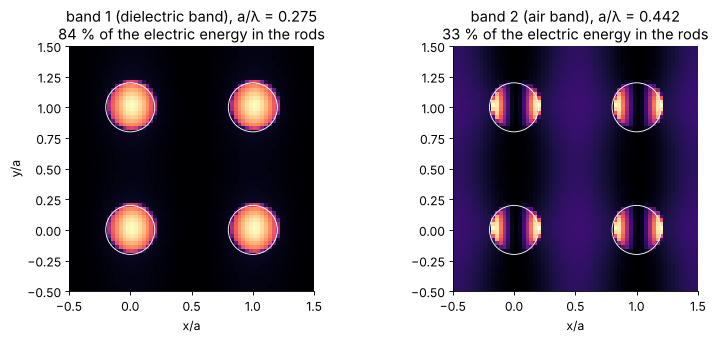

In [9]:
X = fdtd.bloch_modes(grid2, rods, (np.pi, 0.0), band=(1/0.75, 1/0.08), mode="Ez")
f1, f2 = X.frequency[:2]
rng = np.random.default_rng(3)
srcs = [fdtd.PointSource(tuple(rng.random(2) - 0.5), fdtd.GaussianPulse(1/(0.5*(f1 + f2)), 0.4),
                         amplitude=np.exp(2j*np.pi*rng.random())) for _ in range(5)]
dft_x = fdtd.DFTField([1/f1, 1/f2], components=["Ez"], start=40.0)
sim = fdtd.Simulation(fdtd.Grid((1.0, 1.0), 1/32), rods, srcs, [dft_x], mode="Ez",
                      boundaries=(fdtd.Bloch(np.pi), "periodic"))
sim.run(time=400)
x, y = dft_x.coords("Ez")
eps = sim.permittivity("Ez")
fig, ax = plt.subplots(1, 2, figsize=(10, 4.4))
for a, k_, f, name in zip(ax, (0, 1), (f1, f2), ("band 1 (dielectric band)", "band 2 (air band)")):
    F = dft_x.field("Ez")[k_]
    W = eps*np.abs(F)**2
    a.imshow(np.tile(W, (2, 2)).T, origin="lower", extent=(-0.5, 1.5, -0.5, 1.5), cmap="magma")
    for cx in (0, 1):
        for cy in (0, 1):
            a.add_patch(plt.Circle((cx, cy), 0.2, fill=False, ec="w", lw=0.8))
    frac = np.sum(W*(eps > 4))/np.sum(W)
    a.set(title="%s, a/λ = %.3f\n%.0f %% of the electric energy in the rods" % (name, f, 100*frac),
          xlabel="x/a")
ax[0].set_ylabel("y/a")
plt.tight_layout()
print("total run time of the notebook: %.0f s" % (time.perf_counter() - t_start))

Most of the electric energy of band 1 sits in the high-index rods, which
lowers its frequency; band 2 has to be orthogonal to it and puts its
energy into the air, which raises its frequency: the difference is the
gap. Inside the gap, light of the Ez polarization cannot enter the
crystal, which makes it a mirror for every angle; a missing rod becomes a
cavity, a missing row a waveguide that can turn sharp corners.

## Summary

- `fdtd.Bloch(k)` boundaries make the fields complex and launch oblique
  plane waves from line sources; a slab follows `thin_films` at the angle
  of each wavelength to 2e-3.
- `fdtd.DiffractionMonitor` gives the power in each diffraction order;
  lamellar gratings agree with RCWA to about 1e-3 in both polarizations,
  at normal and oblique incidence, across a whole band from one run
  (except right at the Rayleigh anomalies, which need long runs).
- A guided-mode resonance filter reflects a narrow band; FDTD and RCWA
  agree on its position and shape (to 1 nm for the narrower TM peak).
- `fdtd.bloch_modes` gives band structures: the Bragg stack bands match
  the exact ones, and the rod lattice has the known Ez gap of 31 %.

Next (proposals/fdtd.md): photonic crystal waveguides and cavities, a
grating coupler from a fibre into a waveguide, and metasurfaces from
periodic unit cells.